# Correlation of per-gloss F1 with training instance and signer counts

Per-gloss test F1 of one WLASL-2000 run against two counts from the training set it was trained on:
- the number of instances;
- the number of unique signers.

The run is set in [Set params](#set-params). The thesis (§5.5.4/§5.5.5) uses thesis job 4's final
model (`MViTv2_S_16x4_e_5mzfq88e_chained_s42`, corrected `asl2000` split) since 25 Oct 2026; before
that it used `MViTv2_S` `exp000` and `exp002` on `asl2000_cutoff_9_1_indexed`, whose stashes and
figures are kept.

## Imports

In [1]:
import json

import pandas as pd
from IPython.display import display

import src.preprocess as preproc
from src.configs import get_class_list
from src.run_types import (
    AVAIL_SETS,
    AVAIL_SPLITS,
    CUTOFF_9_1_INDEXED_NAMES,
    ONE_INDEXED_SPLITS,
    RESULTS_OUTPUTS,
    RUNS_PATH,
)
from src.stats import (
    create_instances_table,
)
from src.video_dataset import get_wlasl_info
from src.visualise2 import (
    plot_metric_correlation,
    save_fig,
    set_thesis_style,
)

verbosity = 1
def printv(*args, level=1, **kwargs):
    if level <= verbosity:
        print(*args, **kwargs)

## Set params

In [2]:
# splits whose dataset tables are saved below
split_options: list[ONE_INDEXED_SPLITS] = CUTOFF_9_1_INDEXED_NAMES
split_name : ONE_INDEXED_SPLITS = 'asl2000_cutoff_9_1_indexed' # the split shown in "Load stats"
set_name : AVAIL_SETS = 'train'

# The run analysed from "Fetch results" on. Its training counts come from `run_split`, the split
# it was trained on. The earlier thesis runs: run_split 'asl2000_cutoff_9_1_indexed',
# model_name 'MViTv2_S', exp_no '000' or '002'; job 4 (replaced by sweep 2, 16 Nov 2026): run_split
# 'asl2000', model_name 'MViTv2_S_16x4_e', exp_no 'MViTv2_S_16x4_e_5mzfq88e_chained_s42'. The
# thesis's S3D comparison: run_split 'asl2000', model_name 'S3D', exp_no 'S3D_cs9lwmiy_s42'.
run_split: AVAIL_SPLITS = 'asl2000'
model_name = 'MViTv2_S_e' # the thesis's final model: sweep 2's chain, asl2000 stage (Que_v2 job 78)
exp_no = 'MViTv2_S_e_woitlmw6_s42'
checkpoint_num = None # override if multiple runs of the same experiment

classes = get_class_list()
set_thesis_style()

project_name = 'error_analysis'
output_dir = RESULTS_OUTPUTS / project_name

print(f'Split: {split_name} Set: {set_name}')

Split: asl2000_cutoff_9_1_indexed Set: train


## Load stats

Dataset information:

In [3]:
dataset_info = get_wlasl_info(split_name, set_name)
print(json.dumps({k : str(v) for k, v in dataset_info.items()}, indent=4))

{
    "root": "/home/luke/Code/SLR/data/WLASL/WLASL2000",
    "labels": "/home/luke/Code/SLR/data/WLASL/preprocessed/labels/asl2000_cutoff_9_1_indexed",
    "label_suff": "fixed_frange_bboxes.json",
    "set_name": "train"
}


### Show variation of datasets in a table

In [4]:
from src.stats import (
    WLASLClass,
    get_set_stats,
    retrieve_split_data,
    reverse_preproc_format,
)


def split_stats(split: AVAIL_SPLITS) -> dict:
    """Per-gloss instance and signer statistics of each set ('train', 'val', 'test') of `split`."""
    dataset_info = get_wlasl_info(split, 'train')
    labels_dir = dataset_info['labels'].parent
    label_suffix = dataset_info['label_suff']
    set_info = retrieve_split_data(split=split, labels_dir=labels_dir, pattern=f'*{label_suffix}')
    stats = {}
    for key, value in set_info.items():
        set_key = next(s for s in ('train', 'test', 'val') if key.startswith(s))
        instances = [preproc.Instance.model_validate(v) for v in value]
        glosses = reverse_preproc_format(instances, classes=classes)
        stats[set_key] = get_set_stats([WLASLClass.model_validate(g) for g in glosses])
    return stats


all_splits: dict[ONE_INDEXED_SPLITS, dict] = {split: split_stats(split) for split in split_options}
for split, stats in all_splits.items():
    print(f'Split info for {split}')
    display(create_instances_table(stats))
    print('\n', '-'*10)

Split info for asl100_cutoff_9_1_indexed


,Set name,Num instances,Num signers,instances per gloss,signers per gloss
0,test,258,56,[2 - 5],[2 - 4]
1,train,1442,91,[12 - 30],[7 - 15]
2,val,338,69,[3 - 6],[2 - 6]



 ----------
Split info for asl300_cutoff_9_1_indexed


,Set name,Num instances,Num signers,instances per gloss,signers per gloss
0,test,668,74,[2 - 5],[1 - 4]
1,train,3549,104,[9 - 30],[5 - 15]
2,val,901,88,[2 - 6],[2 - 6]



 ----------
Split info for asl1000_cutoff_9_1_indexed


,Set name,Num instances,Num signers,instances per gloss,signers per gloss
0,test,1876,89,[1 - 5],[1 - 4]
1,train,8977,113,[6 - 30],[4 - 15]
2,val,2319,101,[1 - 6],[1 - 6]



 ----------
Split info for asl2000_cutoff_9_1_indexed


,Set name,Num instances,Num signers,instances per gloss,signers per gloss
0,test,2879,105,[1 - 5],[1 - 4]
1,train,14295,117,[5 - 30],[2 - 15]
2,val,3918,109,[1 - 6],[1 - 6]



 ----------


#### Save dataset tables as LaTeX

One `.tex` table per split (train/val/test rows), written to `RESULTS_OUTPUTS / project_name`.

In [5]:
from src.results import get_asset_path, stash_split_name
from src.visualise2 import split_name_mapper

for tab_split, tab_stats in all_splits.items():
    tab_name = stash_split_name(tab_split)  # keeps the file and LaTeX label the thesis uses
    latex_str = create_instances_table(tab_stats).to_latex(
        index=False,
        column_format="lcccc",
        caption=f"Instance and signer counts per set for {split_name_mapper(tab_split)}",
        label=f"tab:instances_{tab_name}",
    )

    tex_path = get_asset_path("instances_table", tab_name, project_name, file_suffix=".tex")
    tex_path.parent.mkdir(parents=True, exist_ok=True)
    tex_path.write_text(latex_str)

    printv(f"Saved to {tex_path}")
    printv(latex_str, level=2)

Saved to /home/luke/Code/SLR/src/results/outputs/error_analysis/instances_table_asl100_cutoff_9.tex
Saved to /home/luke/Code/SLR/src/results/outputs/error_analysis/instances_table_asl300_cutoff_9.tex
Saved to /home/luke/Code/SLR/src/results/outputs/error_analysis/instances_table_asl1000_cutoff_9.tex
Saved to /home/luke/Code/SLR/src/results/outputs/error_analysis/instances_table_asl2000_cutoff_9.tex


## Fetch results and create dataframes

In [6]:
per_set_stats = split_stats(run_split)

### Fetch results

#### Stash the run's results

In [7]:
from src.results import format_exp_label, get_out_stub, get_stash_path, stash_from_saved

exp_label = format_exp_label(exp_no)
stub = get_out_stub(run_split, model_name, exp_label, checkpoint_num)
stash_p = get_stash_path(stub)
if not stash_p.exists():
    # testing.py's per-run results; exp000's stash came from rerunning inference instead
    saved_p = RUNS_PATH / run_split / model_name / exp_label / 'results' / 'cls_rep_all_targets_preds.json'
    stash_from_saved(saved_p, checkpoint_num)
print(f'Stash: {stash_p}')

Stash: stashed_results/asl2000_MViTv2_S_e_MViTv2_S_e_woitlmw6_s42_results.json


In [8]:
from src.results import load_json

all_results = {k : v for k, v in load_json(stash_p).items()}
print(all_results.keys())

dict_keys(['cls_report', 'all_targets', 'all_preds'])


### Create F1 Dataframe

In [9]:
cls_rep = all_results["cls_report"]
all_targets = all_results["all_targets"]
all_preds = all_results["all_preds"]

exclude_keys = {"accuracy", "macro avg", "weighted avg"}

per_class_rows = []
for key, metrics_dict in cls_rep.items():
    if key in exclude_keys:
        continue
    # cls_rep keys are either stringified numeric labels (map via classes list)
    # or already gloss strings -- handle both
    if key.isdigit():
        gloss = classes[int(key)]
    else:
        gloss = key
    per_class_rows.append({"gloss": gloss, "f1": metrics_dict["f1-score"]})

f1_df = pd.DataFrame(per_class_rows)
printv(f"Loaded F1 scores for {len(f1_df)} classes")
f1_df.head()

Loaded F1 scores for 2000 classes


,gloss,f1
0,book,0.857143
1,drink,0.571429
2,computer,0.666667
3,before,0.000000
4,chair,0.571429


### Create instance and signer count  Dataframe

In [10]:
train_stats = per_set_stats['train']

stats_rows = []
for gloss, stat in train_stats['per_instance_stats'].items():
    num_instances = stat["num_instances"]
    signers_distribution = stat["signers_distribution"]  # {signer_id: occurrence_count}
    num_signers = len(signers_distribution)  # unique signer count
    stats_rows.append({"gloss": gloss, "num_instances": num_instances, "num_signers": num_signers})

stats_df = pd.DataFrame(stats_rows)
printv(f"Loaded stats for {len(stats_df)} classes")
stats_df.head()

Loaded stats for 2000 classes


,gloss,num_instances,num_signers
0,book,30,14
1,drink,25,15
2,computer,20,12
3,before,18,13
4,chair,19,11


### Create merged dataframe

In [11]:
merged = f1_df.merge(stats_df, on="gloss", how="inner")

if len(merged) != len(f1_df):
    missing = set(f1_df["gloss"]) - set(merged["gloss"])
    print(f"WARNING: {len(missing)} glosses from results not found in training stats: {missing}")

merged.head()

,gloss,f1,num_instances,num_signers
0,book,0.857143,30,14
1,drink,0.571429,25,15
2,computer,0.666667,20,12
3,before,0.000000,18,13
4,chair,0.571429,19,11


## F1 vs. instance count

number of examples

Saved to /home/luke/Code/SLR/src/results/outputs/error_analysis/corr_mat_asl2000_MViTv2_S_e_MViTv2_S_e_woitlmw6_s42_.pdf
Instance count correlation: tau=0.157, p=3.570e-18


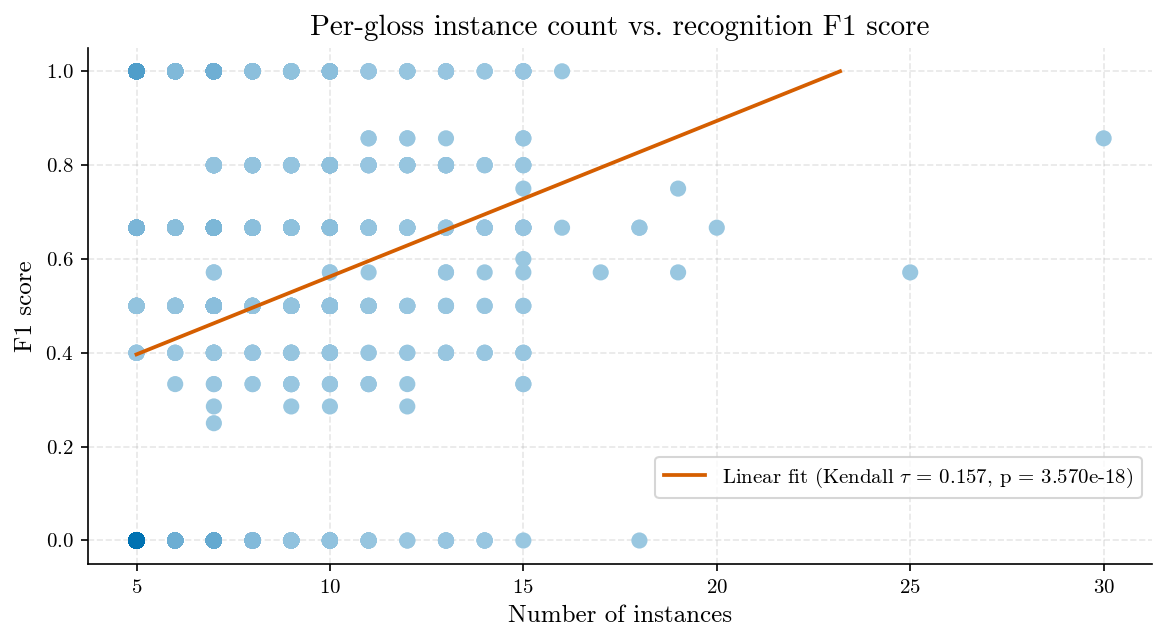

In [12]:
from src.results import get_asset_path

instance_plot_path = get_asset_path('corr_mat', stub, project_name)
fig1, ax1, tau_inst, p_inst = plot_metric_correlation(
    merged["num_instances"],
    merged["f1"],
    title="Per-gloss instance count vs. recognition F1 score",
    xlabel="Number of instances",
    y_clip=(0, 1),
    legend_top_y=0.2,
)
save_fig(fig1, instance_plot_path)
printv(f"Saved to {instance_plot_path}")
print(f"Instance count correlation: tau={tau_inst:.3f}, p={p_inst:.3e}")

## F1 vs. signer count

number of unique signer ids.

Saved to /home/luke/Code/SLR/src/results/outputs/error_analysis/corr_signers_asl2000_MViTv2_S_e_MViTv2_S_e_woitlmw6_s42_.pdf
Signer count correlation: tau=0.173, p=5.724e-22


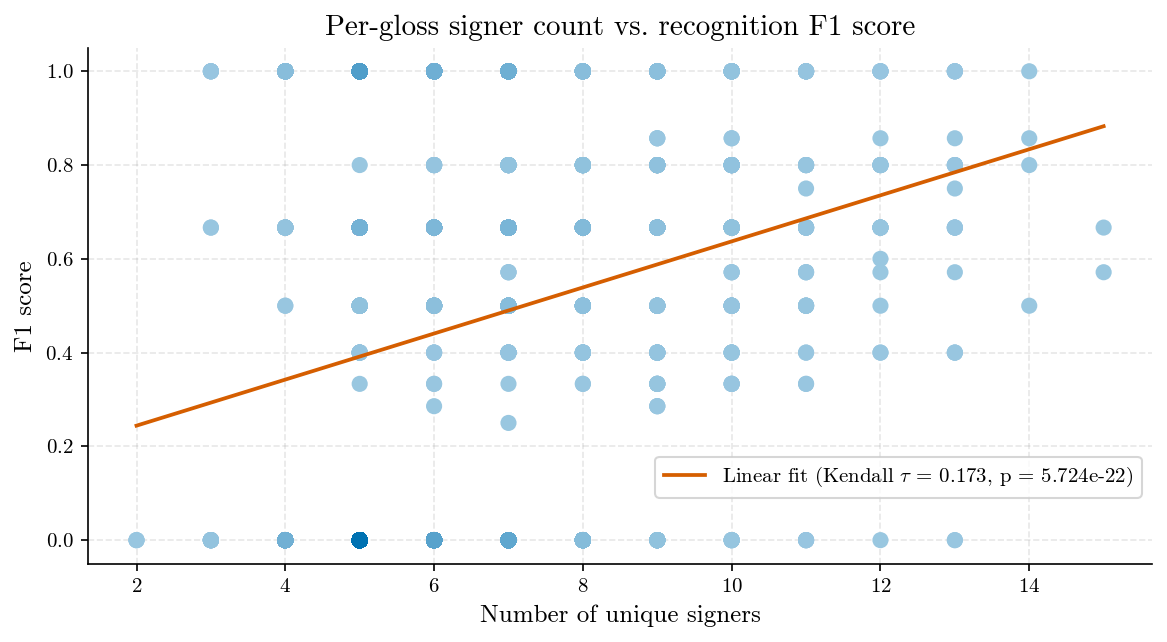

In [13]:
signers_plot_path = get_asset_path('corr_signers', stub, project_name)
fig2, ax2, tau_signers, p_signers = plot_metric_correlation(
    merged["num_signers"],
    merged["f1"],
    title="Per-gloss signer count vs. recognition F1 score",
    xlabel="Number of unique signers",
    y_clip=(0, 1),
    legend_top_y=0.2,
)
save_fig(fig2, signers_plot_path)
printv(f"Saved to {signers_plot_path}")
print(f"Signer count correlation: tau={tau_signers:.3f}, p={p_signers:.3e}")

## Collect performance outliers

In [14]:
def performance_outliers(
    merged: pd.DataFrame,
    max_signers: int = 3,
    min_f1: float = 0.80,
    min_signers: int = 13,
    max_f1: float = 0.20,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """The glosses doing better or worse than their training data suggests.

    Over-achievers have at most `max_signers` training signers and F1 >= `min_f1`; under-achievers
    have at least `min_signers` and F1 <= `max_f1`. The defaults are the thesis's rule (§5.5.5).
    Columns are named as in the stash `eda_performers.ipynb` reads.
    """
    df = merged.rename(
        columns={'gloss': 'Gloss', 'num_instances': 'Instances', 'num_signers': 'Signers', 'f1': 'F1_Score'}
    )[['Gloss', 'Instances', 'Signers', 'F1_Score']]
    over = df.loc[(df['Signers'] <= max_signers) & (df['F1_Score'] >= min_f1)]
    under = df.loc[(df['Signers'] >= min_signers) & (df['F1_Score'] <= max_f1)]
    return (
        over.sort_values(['F1_Score', 'Signers'], ascending=[False, True]),
        under.sort_values(['F1_Score', 'Signers'], ascending=[True, False]),
    )


over_df, under_df = performance_outliers(merged)
print(f'{len(over_df)} over-achievers, {len(under_df)} under-achievers')
display(over_df, under_df)

5 over-achievers, 2 under-achievers


,Gloss,Instances,Signers,F1_Score
1344,come here,5,3,1.0
1591,wash face,5,3,1.0
1842,obsess,5,3,1.0
1850,overcome,5,3,1.0
1869,post,5,3,1.0


,Gloss,Instances,Signers,F1_Score
3,before,18,13,0.0
61,eat,14,13,0.0


### Save performance outliers file

Named by the run's stub. exp000's was saved before 25 Oct 2026 with an under-achiever threshold of
6 signers; its first four are the thesis's ≥ 13-signer ones.

In [15]:
from src.results import stash_json

outliers_p = get_stash_path(stub, base_name='performance_outliers')
stash_json(
    {'overachievers': over_df.to_dict(orient='records'), 'underachievers': under_df.to_dict(orient='records')},
    outliers_p,
)
print(f'Saved outliers to {outliers_p}')

Saved outliers to stashed_results/asl2000_MViTv2_S_e_MViTv2_S_e_woitlmw6_s42_performance_outliers.json


### Instance–signer correlation

In [16]:
from scipy.stats import kendalltau

print("inst vs signers:", kendalltau(merged.num_instances, merged.num_signers))
rec = pd.DataFrame([{"gloss": classes[int(k)] if k.isdigit() else k, "recall": v["recall"]} for k, v in cls_rep.items() if k not in exclude_keys])
m2 = rec.merge(stats_df, on="gloss")
print("recall vs inst:", kendalltau(m2.num_instances, m2.recall))
print("recall vs signers:", kendalltau(m2.num_signers, m2.recall))

inst vs signers: SignificanceResult(statistic=np.float64(0.8723510018570542), pvalue=np.float64(0.0))
recall vs inst: SignificanceResult(statistic=np.float64(0.13722665563053896), pvalue=np.float64(3.4696269882907047e-13))
recall vs signers: SignificanceResult(statistic=np.float64(0.16300036146101315), pvalue=np.float64(3.2209911789917423e-18))
